# H15 — Brent crude oil forecasting

**Objective.** Evaluate 15-trading-day-ahead Brent spot-price forecasts against a no-change (random-walk) benchmark. The notebook reports statistical accuracy, exploratory model extensions and a simplified economic evaluation.

**Evaluation design.** Rolling-origin forecasts; validation origins from January 2024 through December 2025 (targets no later than 31 December 2025); test origins from January through September 2026 (targets no later than 30 September 2026). The shared backtest treats `end_date` as exclusive. Model inputs and matured training targets must be available at each forecast origin.

**Reproducibility.** Run from the project `notebooks/` directory with the group `src/` package available one level above. Figures and CSV outputs are written to `../results/`. The 2026 period has been examined during exploratory development and should not be described as an untouched holdout.

In [1]:

import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import load_dataset
from src.features import make_lag_features
from src.backtest import walk_forward

from src.models import (
    random_walk_forecast,
    historical_mean_forecast,
    ar1_forecast,
    var_forecast,
    xgb_forecast
)

from src.metrics import (
    accuracy_metrics,
    directional_metrics,
    compare_models
)

H = 15

print("H15 notebook ready!")


H15 notebook ready!


## 1. Data preparation

Load the shared dataset, construct log returns and selected log-level predictors, and build the lagged S1 feature matrix. Nonpositive observations cannot be logged and are excluded during cleaning.

In [2]:

data = load_dataset()

X = pd.DataFrame(index=data.index)

for col in ["brent_spot", "wti", "usd", "sp500"]:
    X[col] = np.log(data[col].where(data[col] > 0)).diff()

for col in ["vix", "ovx", "epu", "gpr"]:
    X[col] = np.log(data[col].where(data[col] > 0))

X = X.dropna()

df_var = X.rename(columns={"brent_spot": "log_return"})
df_var["brent_spot"] = data["brent_spot"]

features_s1 = make_lag_features(
    df_var,
    cols=["log_return", "wti", "sp500"],
    lags=3
)

print("Cleaned observations:", len(df_var))
print("First date:", df_var.index.min())
print("Last date:", df_var.index.max())
print("XGBoost features:", features_s1.shape[1])


/Users/jingwen/Downloads/Sample-Taxed-main-2/.venv/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/jingwen/Downloads/Sample-Taxed-main-2/.venv/lib/python3.13/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/Users/jingwen/Downloads/Sample-Taxed-main-2/.venv/lib/python3.13/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more

Cleaned observations: 4912
First date: 2007-05-10 00:00:00
Last date: 2026-10-27 00:00:00
XGBoost features: 9


## 2. Evaluation periods and baseline

Define the common H15 validation and test windows, then evaluate the random-walk forecast.

In [3]:

val_args = dict(
    horizon=H,
    start_date="2024-01-01",
    end_date="2025-12-31",
    target_end_date="2025-12-31"
)

test_args = dict(
    horizon=H,
    start_date="2026-01-01",
    end_date="2026-09-30",
    target_end_date="2026-09-30"
)

print("Validation and test periods configured.")


Validation and test periods configured.


In [4]:

rw_val = walk_forward(
    df=df_var,
    forecast_funct=random_walk_forecast,
    **val_args
)

rw_test = walk_forward(
    df=df_var,
    forecast_funct=random_walk_forecast,
    **test_args
)

print("Validation forecasts:", len(rw_val))
print("Test forecasts:", len(rw_test))

print("\nValidation accuracy:")
print(accuracy_metrics(rw_val))

print("\nTest accuracy:")
print(accuracy_metrics(rw_test))


Validation forecasts: 492
Test forecasts: 174

Validation accuracy:
{'MAE': np.float64(3.4802845528455286), 'RMSE': np.float64(4.505205796441788), 'MAPE': np.float64(4.635618225064395)}

Test accuracy:
{'MAE': np.float64(13.731781609195401), 'RMSE': np.float64(17.441064355768802), 'MAPE': np.float64(14.096806969757402)}


## 3. Core model comparison

Compare random walk, historical mean, AR(1), VAR(3) and XGBoost on validation, then evaluate their unchanged specifications on the 2026 test period.

In [5]:

# H15 validation model comparison

val_models = {
    "Random Walk": rw_val,

    "Historical Mean": walk_forward(
        df_var,
        forecast_funct=historical_mean_forecast,
        lookback=3000,
        **val_args
    ),

    "AR(1)": walk_forward(
        df_var,
        forecast_funct=ar1_forecast,
        lookback=3000,
        **val_args
    ),

    "VAR S1 p=3": walk_forward(
        df_var,
        forecast_funct=var_forecast,
        cols=["log_return", "wti", "sp500"],
        lags=3,
        lookback=3000,
        **val_args
    ),

    "XGBoost S1": walk_forward(
        df_var,
        forecast_funct=xgb_forecast,
        features=features_s1,
        lookback=3000,
        n_estimators=50,
        max_depth=1,
        learning_rate=0.05,
        min_child_weight=1,
        **val_args
    )
}

val_summary = compare_models(val_models, horizon=H)

display(
    val_summary[
        ["MAE", "RMSE", "MAPE", "directional_accuracy"]
    ].sort_values("MAPE")
)


,MAE,RMSE,MAPE,directional_accuracy
model,,,,
XGBoost S1,3.482838,4.517218,4.633417,0.504065
Random Walk,3.480285,4.505206,4.635618,0.004065
VAR S1 p=3,3.493913,4.523540,4.657013,0.504065
Historical Mean,3.512944,4.544596,4.684680,0.445122
AR(1),3.522187,4.554217,4.698443,0.400407


In [6]:

# H15 standardized test: January–September 2026

test_models = {
    "Random Walk": rw_test,

    "Historical Mean": walk_forward(
        df_var,
        forecast_funct=historical_mean_forecast,
        lookback=3000,
        **test_args
    ),

    "AR(1)": walk_forward(
        df_var,
        forecast_funct=ar1_forecast,
        lookback=3000,
        **test_args
    ),

    "VAR S1 p=3": walk_forward(
        df_var,
        forecast_funct=var_forecast,
        cols=["log_return", "wti", "sp500"],
        lags=3,
        lookback=3000,
        **test_args
    ),

    "XGBoost S1": walk_forward(
        df_var,
        forecast_funct=xgb_forecast,
        features=features_s1,
        lookback=3000,
        n_estimators=50,
        max_depth=1,
        learning_rate=0.05,
        min_child_weight=1,
        **test_args
    )
}

test_summary = compare_models(test_models, horizon=H)

display(
    test_summary[
        ["MAE", "RMSE", "MAPE", "directional_accuracy"]
    ].sort_values("MAPE")
)


,MAE,RMSE,MAPE,directional_accuracy
model,,,,
Historical Mean,13.699840,17.421271,14.078843,0.666667
AR(1),13.711422,17.413980,14.085016,0.603448
Random Walk,13.731782,17.441064,14.096807,0.000000
VAR S1 p=3,13.786077,17.447025,14.166206,0.482759
XGBoost S1,14.149264,17.638258,14.634270,0.356322


### Test-period chart and core exports

The figure plots forecasts against actual Brent prices by **target date**. The initial CSV export covers the five core models; the consolidated table at the end also includes exploratory extensions.

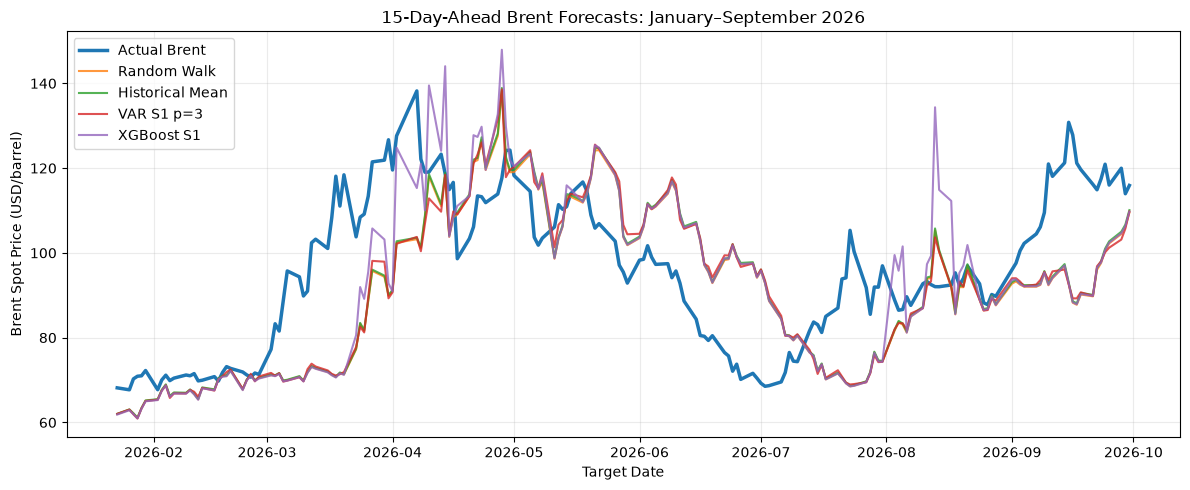

H15 test outputs saved.


In [7]:

from pathlib import Path

output_dir = Path("../results")
output_dir.mkdir(exist_ok=True)

plt.figure(figsize=(12, 5))

plt.plot(
    rw_test["target_date"],
    rw_test["actual"],
    label="Actual Brent",
    linewidth=2.5
)

for name in ["Random Walk", "Historical Mean", "VAR S1 p=3", "XGBoost S1"]:
    results = test_models[name]
    plt.plot(
        results["target_date"],
        results["forecast"],
        label=name,
        alpha=0.8
    )

plt.title("15-Day-Ahead Brent Forecasts: January–September 2026")
plt.xlabel("Target Date")
plt.ylabel("Brent Spot Price (USD/barrel)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(output_dir / "h15_test_comparison.png", dpi=200)
plt.show()

test_summary.to_csv(output_dir / "h15_test_metrics.csv")

for name, results in test_models.items():
    filename = name.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("=", "")
    results.to_csv(
        output_dir / f"h15_{filename}_test.csv",
        index=False
    )

print("H15 test outputs saved.")


## 4. Exploratory volatility analysis

Compare realized volatility between periods and assess a trailing-window volatility proxy against subsequently realized volatility. This is not a separately validated GARCH forecast.

In [8]:
val_returns = df_var.loc[
    "2024-01-01":"2025-12-31", "log_return"
]

test_returns = df_var.loc[
    "2026-01-01":"2026-09-30", "log_return"
]

vol_comparison = pd.DataFrame({
    "Period": ["Validation 2024-2025", "Test 2026"],
    "Daily volatility": [
        val_returns.std(),
        test_returns.std()
    ],
    "Annualized volatility": [
        val_returns.std() * np.sqrt(252),
        test_returns.std() * np.sqrt(252)
    ]
})

display(vol_comparison)

print(
    "Test/validation daily volatility ratio:",
    round(test_returns.std() / val_returns.std(), 2)
)


,Period,Daily volatility,Annualized volatility
0,Validation 2024-2025,0.018063,0.286738
1,Test 2026,0.043186,0.685560


Test/validation daily volatility ratio: 2.39


In [9]:

# H15: rolling-origin volatility forecast

H = 15
returns = df_var["log_return"]

rows = []

for _, forecast_row in rw_test.iterrows():
    origin = forecast_row["origin_date"]
    target = forecast_row["target_date"]

    history = returns.loc[:origin].tail(20)

    if len(history) < 20 or history.isna().any():
        continue

    # Forecast daily volatility from information available at origin
    predicted_daily_vol = history.std()

    # Constant-volatility approximation for cumulative H-day returns
    predicted_h_vol = predicted_daily_vol * np.sqrt(H)

    # Realized volatility over the following H observations
    origin_idx = df_var.index.get_loc(origin)
    future_returns = returns.iloc[origin_idx + 1:origin_idx + H + 1]

    realized_daily_vol = future_returns.std()
    realized_h_vol = realized_daily_vol * np.sqrt(H)

    rows.append({
        "origin_date": origin,
        "target_date": target,
        "predicted_h_vol": predicted_h_vol,
        "realized_h_vol": realized_h_vol
    })

vol_results = pd.DataFrame(rows)

display(vol_results.head())

print("Forecasts:", len(vol_results))
print(
    "Correlation:",
    vol_results["predicted_h_vol"].corr(
        vol_results["realized_h_vol"]
    )
)


,origin_date,target_date,predicted_h_vol,realized_h_vol
0,2026-01-02,2026-01-23,0.051456,0.091243
1,2026-01-05,2026-01-26,0.053327,0.091457
2,2026-01-06,2026-01-27,0.054223,0.094432
3,2026-01-07,2026-01-28,0.055431,0.090622
4,2026-01-08,2026-01-29,0.063117,0.086353


Forecasts: 174
Correlation: 0.32110630825215847


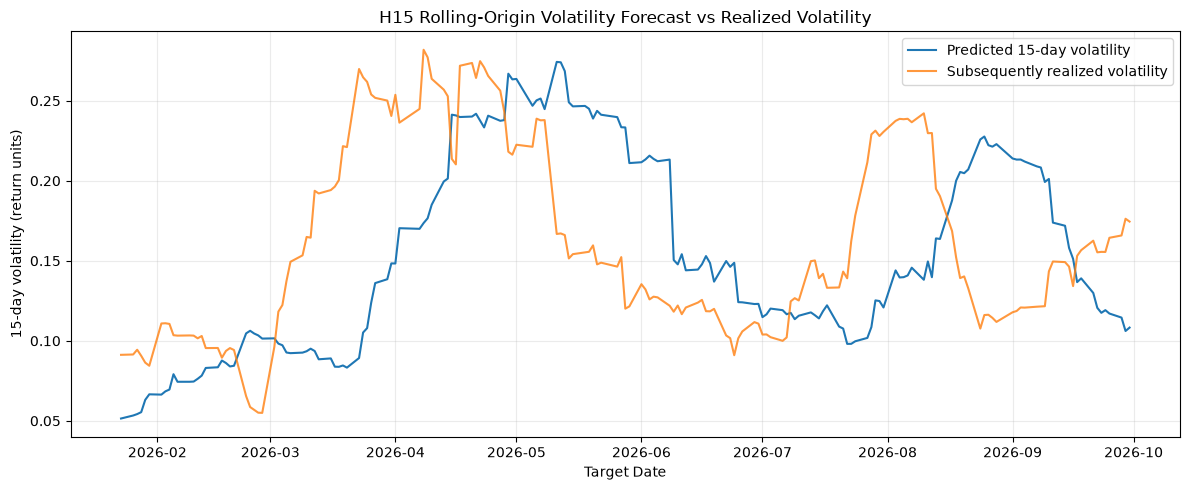

In [10]:

plt.figure(figsize=(12, 5))

plt.plot(
    vol_results["target_date"],
    vol_results["predicted_h_vol"],
    label="Predicted 15-day volatility"
)

plt.plot(
    vol_results["target_date"],
    vol_results["realized_h_vol"],
    label="Subsequently realized volatility",
    alpha=0.8
)

plt.title("H15 Rolling-Origin Volatility Forecast vs Realized Volatility")
plt.xlabel("Target Date")
plt.ylabel("15-day volatility (return units)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [11]:

# Rolling volatility forecast diagnostics

error = (
    vol_results["predicted_h_vol"]
    - vol_results["realized_h_vol"]
)

print("Mean forecast bias:", round(error.mean(), 4))
print("Mean absolute error:", round(error.abs().mean(), 4))
print("RMSE:", round(np.sqrt((error ** 2).mean()), 4))

print(
    "Underprediction frequency:",
    round((error < 0).mean() * 100, 2),
    "%"
)


Mean forecast bias: -0.007
Mean absolute error: 0.0581
RMSE: 0.0697
Underprediction frequency: 55.17 %


## 5. Exploratory extensions: momentum and ARIMA

Investigate direct momentum and rolling ARIMA(4,1,1) as additional H15 challengers. The extensions were developed after examining the initial model comparisons.

In [12]:
from src.models import direct_lags_forecast


# Exploratory H15 direct momentum regression
# Evaluate validation first, not test

direct15_val = walk_forward(
    df=df_var,
    forecast_funct=direct_lags_forecast,
    short=5,
    long=15,
    nonoverlap=True,
    lookback=3000,
    **val_args
)

print("Direct momentum regression — validation")
print(accuracy_metrics(direct15_val))

print("\nRandom walk — validation")
print(accuracy_metrics(rw_val))


Direct momentum regression — validation
{'MAE': np.float64(3.6428414315382738), 'RMSE': np.float64(4.72920642195563), 'MAPE': np.float64(4.848188214091772)}

Random walk — validation
{'MAE': np.float64(3.4802845528455286), 'RMSE': np.float64(4.505205796441788), 'MAPE': np.float64(4.635618225064395)}


In [13]:

from statsmodels.tsa.arima.model import ARIMA

print("ARIMA imported successfully!")


ARIMA imported successfully!


In [14]:

def arima_forecast(
    df,
    origin_idx,
    horizon,
    fit_idx,
    order=(4, 1, 1),
    lookback=750
):
    """
    Rolling-origin ARIMA forecast of Brent log prices.

    Fits only observations available at the forecast origin.
    Returns a price forecast horizon trading observations ahead.
    """

    if fit_idx > origin_idx:
        raise ValueError("fit_idx cannot exceed origin_idx")

    prices = df["brent_spot"].iloc[
        fit_idx - lookback + 1:fit_idx + 1
    ]

    if len(prices) < lookback or (prices <= 0).any():
        raise ValueError("Invalid ARIMA training window")

    log_prices = np.log(prices)

    model = ARIMA(
        log_prices.to_numpy(),
        order=order,
        trend="n",
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit()

    predicted_log_price = fitted.forecast(
        steps=horizon
    )[-1]

    return float(np.exp(predicted_log_price))


print("ARIMA forecasting function ready!")


ARIMA forecasting function ready!


In [15]:

import warnings
import time

start_time = time.time()

with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    arima15_val = walk_forward(
        df=df_var,
        forecast_funct=arima_forecast,
        order=(4, 1, 1),
        lookback=750,
        **val_args
    )

print("ARIMA forecasts:", len(arima15_val))
print("Elapsed seconds:", round(time.time() - start_time, 1))

print("\nARIMA H15 validation:")
print(accuracy_metrics(arima15_val))

print("\nRandom walk H15 validation:")
print(accuracy_metrics(rw_val))


ARIMA forecasts: 492
Elapsed seconds: 47.6

ARIMA H15 validation:
{'MAE': np.float64(3.4713639212972702), 'RMSE': np.float64(4.495497004326603), 'MAPE': np.float64(4.622530662449688)}

Random walk H15 validation:
{'MAE': np.float64(3.4802845528455286), 'RMSE': np.float64(4.505205796441788), 'MAPE': np.float64(4.635618225064395)}


In [16]:

assert len(arima15_val) == len(rw_val)

assert (
    arima15_val["target_date"].reset_index(drop=True)
    .equals(
        rw_val["target_date"].reset_index(drop=True)
    )
)

print("ARIMA and Random Walk target dates aligned.")


ARIMA and Random Walk target dates aligned.


In [17]:

import time
import warnings

start_time = time.time()

with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    arima15_test = walk_forward(
        df=df_var,
        forecast_funct=arima_forecast,
        order=(4, 1, 1),
        lookback=750,
        **test_args
    )

print("Test forecasts:", len(arima15_test))
print("Elapsed seconds:", round(time.time() - start_time, 1))

print("\nARIMA H15 test:")
print(accuracy_metrics(arima15_test))

print("\nRandom Walk H15 test:")
print(accuracy_metrics(rw_test))


Test forecasts: 174
Elapsed seconds: 16.9

ARIMA H15 test:
{'MAE': np.float64(13.776039494832338), 'RMSE': np.float64(17.48607309490898), 'MAPE': np.float64(14.151453874113681)}

Random Walk H15 test:
{'MAE': np.float64(13.731781609195401), 'RMSE': np.float64(17.441064355768802), 'MAPE': np.float64(14.096806969757402)}


## 6. Economic evaluation and trading sensitivity

Illustrative long/short positions are generated from forecast signs and evaluated on non-overlapping schedules. These use spot-price changes as a proxy, simplified costs and only about 11–12 trades per schedule; they are **not executable futures P&L**. Compare offsets rather than highlighting the best one.

In [18]:

import numpy as np
import pandas as pd

economic_models = {
    **test_models,
    "ARIMA(4,1,1)": arima15_test
}

def economic_backtest(results, horizon=15, cost=0.0005, offset=0):
    """
    Simplified non-overlapping directional strategy.
    Long if forecast > origin price.
    Short if forecast < origin price.
    Flat otherwise.

    cost = 0.0005 per unit of position turnover.
    """

    trades = results.iloc[offset::horizon].copy()

    if trades.empty:
        raise ValueError("No trades for this offset")

    trades["position"] = np.sign(
        trades["forecast"] - trades["origin_price"]
    )

    trades["market_return"] = (
        trades["actual"] / trades["origin_price"] - 1
    )

    trades["gross_return"] = (
        trades["position"] * trades["market_return"]
    )

    previous_position = trades["position"].shift().fillna(0)

    # Entry/exit turnover; charge for final liquidation too
    trades["turnover"] = (
        trades["position"] - previous_position
    ).abs()

    trades["net_return"] = (
        trades["gross_return"] - cost * trades["turnover"]
    )

    # Final exit cost
    trades.iloc[-1, trades.columns.get_loc("net_return")] -= (
        cost * abs(trades["position"].iloc[-1])
    )

    trades["wealth"] = (1 + trades["net_return"]).cumprod()
    trades["drawdown"] = (
        trades["wealth"] / trades["wealth"].cummax().clip(lower=1)
        - 1
    )

    periods_per_year = 252 / horizon

    vol = trades["net_return"].std(ddof=1)

    sharpe = (
        trades["net_return"].mean() / vol
        * np.sqrt(periods_per_year)
        if pd.notna(vol) and vol > 0
        else np.nan
    )

    return {
        "trades": len(trades),
        "total_return": trades["wealth"].iloc[-1] - 1,
        "sharpe": sharpe,
        "max_drawdown": trades["drawdown"].min(),
        "win_rate": (trades["net_return"] > 0).mean()
    }


economic_summary = pd.DataFrame({
    name: economic_backtest(results, horizon=H)
    for name, results in economic_models.items()
}).T

display(economic_summary.round(4))


,trades,total_return,sharpe,max_drawdown,win_rate
Random Walk,12.0,0.0000,NaN,0.0000,0.0000
Historical Mean,12.0,0.9290,1.5765,-0.3929,0.7500
AR(1),12.0,0.9290,1.5765,-0.3929,0.7500
VAR S1 p=3,12.0,0.4671,1.0757,-0.3858,0.5833
XGBoost S1,12.0,-0.5435,-0.9629,-0.6575,0.3333
"ARIMA(4,1,1)",12.0,3.6856,4.5075,-0.0390,0.8333


In [19]:

# Check all 15 possible non-overlapping starting offsets

rows = []

for name, results in economic_models.items():
    for offset in range(H):
        metrics = economic_backtest(
            results,
            horizon=H,
            offset=offset
        )

        rows.append({
            "model": name,
            "offset": offset,
            **metrics
        })

offset_results = pd.DataFrame(rows)

offset_summary = offset_results.groupby("model").agg(
    mean_sharpe=("sharpe", "mean"),
    min_sharpe=("sharpe", "min"),
    max_sharpe=("sharpe", "max"),
    mean_total_return=("total_return", "mean"),
    mean_max_drawdown=("max_drawdown", "mean")
)

display(offset_summary.round(4))


,mean_sharpe,min_sharpe,max_sharpe,mean_total_return,mean_max_drawdown
model,,,,,
AR(1),1.1259,-0.4398,1.9030,0.6460,-0.4150
"ARIMA(4,1,1)",-0.2612,-2.9631,4.5075,-0.0323,-0.5497
Historical Mean,1.4516,1.1486,1.7311,0.8348,-0.4019
Random Walk,NaN,NaN,NaN,0.0000,0.0000
VAR S1 p=3,-0.0140,-1.9814,1.3056,-0.0628,-0.5257
XGBoost S1,-1.1157,-2.6549,0.7504,-0.5283,-0.6841


In [20]:

# Overlap check
for name, results in economic_models.items():

    trades = results.iloc[::H].copy().reset_index(drop=True)

    overlaps = (
        trades["target_date"].iloc[:-1].to_numpy()
        > trades["origin_date"].iloc[1:].to_numpy()
    )

    print(
        name,
        "| trades:", len(trades),
        "| overlapping periods:", overlaps.sum()
    )


Random Walk | trades: 12 | overlapping periods: 0
Historical Mean | trades: 12 | overlapping periods: 0
AR(1) | trades: 12 | overlapping periods: 0
VAR S1 p=3 | trades: 12 | overlapping periods: 0
XGBoost S1 | trades: 12 | overlapping periods: 0
ARIMA(4,1,1) | trades: 12 | overlapping periods: 0


## 7. Exploratory ARIMA–random-walk blend

Check whether shrinking ARIMA forecasts toward the random-walk price anchor improves validation errors.

In [21]:

# H15 ARIMA + Random Walk hybrid
# Validation-only weight comparison

weights = [0, 0.25, 0.50, 0.75, 1.0]

def hybrid_forecast_results(rw, arima, weight):
    keys = ["origin_date", "target_date"]

    merged = rw.merge(
        arima[keys + ["forecast"]],
        on=keys,
        suffixes=("_rw", "_arima"),
        validate="one_to_one"
    )

    assert len(merged) == len(rw) == len(arima)

    result = merged[
        keys + ["origin_price", "actual"]
    ].copy()

    result["forecast"] = (
        merged["forecast_rw"]
        + weight * (
            merged["forecast_arima"]
            - merged["forecast_rw"]
        )
    )

    return result[
        keys + ["origin_price", "forecast", "actual"]
    ]

hybrid_val_results = {}

for w in weights:
    hybrid_val_results[w] = hybrid_forecast_results(
        rw_val,
        arima15_val,
        w
    )

hybrid_val_table = pd.DataFrame({
    w: accuracy_metrics(result)
    for w, result in hybrid_val_results.items()
}).T

hybrid_val_table.index.name = "ARIMA weight"

display(hybrid_val_table.round(5))


,MAE,RMSE,MAPE
ARIMA weight,,,
0.00,3.48028,4.50521,4.63562
0.25,3.47782,4.50227,4.63201
0.50,3.47536,4.49967,4.62841
0.75,3.47307,4.49741,4.62506
1.00,3.47136,4.49550,4.62253


In [22]:

# Inspect ARIMA's individual H15 trades (offset 0)

arima_trades = arima15_test.iloc[::H].copy().reset_index(drop=True)

arima_trades["predicted_return"] = (
    arima_trades["forecast"] / arima_trades["origin_price"] - 1
)

arima_trades["actual_return"] = (
    arima_trades["actual"] / arima_trades["origin_price"] - 1
)

arima_trades["position"] = np.sign(
    arima_trades["predicted_return"]
)

arima_trades["gross_strategy_return"] = (
    arima_trades["position"] * arima_trades["actual_return"]
)

display(
    arima_trades[
        [
            "origin_date",
            "target_date",
            "origin_price",
            "forecast",
            "actual",
            "predicted_return",
            "actual_return",
            "position",
            "gross_strategy_return"
        ]
    ].round(4)
)


/var/folders/zc/msw43vhx5n90s_3fp97cqxdw0000gn/T/ipykernel_9272/4286378552.py:34: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(4)


,origin_date,target_date,origin_price,forecast,actual,predicted_return,actual_return,position,gross_strategy_return
0,2026-01-02,2026-01-23,61.98,62.0715,68.16,0.0015,0.0997,1.0,0.0997
1,2026-01-23,2026-02-13,68.16,68.2346,69.96,0.0011,0.0264,1.0,0.0264
2,2026-02-13,2026-03-06,69.96,70.0246,95.74,0.0009,0.3685,1.0,0.3685
3,2026-03-06,2026-03-27,95.74,96.1710,121.47,0.0045,0.2687,1.0,0.2687
4,2026-03-27,2026-04-21,121.47,121.2989,106.14,-0.0014,-0.1262,-1.0,0.1262
5,2026-04-21,2026-05-13,106.14,105.9096,110.28,-0.0022,0.0390,-1.0,-0.0390
6,2026-05-13,2026-06-04,110.28,109.8940,98.98,-0.0035,-0.1025,-1.0,0.1025
7,2026-06-04,2026-06-25,98.98,98.9175,73.74,-0.0006,-0.2550,-1.0,0.2550
8,2026-06-25,2026-07-16,73.74,73.8340,81.23,0.0013,0.1016,1.0,0.1016
9,2026-07-16,2026-08-06,81.23,81.2530,89.65,0.0003,0.1037,1.0,0.1037


In [23]:

# Identify largest winning and losing trades

print("Largest winning trades:")
display(
    arima_trades.nlargest(
        5, "gross_strategy_return"
    )[
        [
            "origin_date",
            "target_date",
            "position",
            "actual_return",
            "gross_strategy_return"
        ]
    ]
)

print("Largest losing trades:")
display(
    arima_trades.nsmallest(
        5, "gross_strategy_return"
    )[
        [
            "origin_date",
            "target_date",
            "position",
            "actual_return",
            "gross_strategy_return"
        ]
    ]
)

print(
    "Gross directional hit rate:",
    round(
        (arima_trades["gross_strategy_return"] > 0).mean() * 100,
        2
    ),
    "%"
)


Largest winning trades:


,origin_date,target_date,position,actual_return,gross_strategy_return
2,2026-02-13,2026-03-06,1.0,0.368496,0.368496
11,2026-08-27,2026-09-18,1.0,0.326902,0.326902
3,2026-03-06,2026-03-27,1.0,0.268749,0.268749
7,2026-06-04,2026-06-25,-1.0,-0.255001,0.255001
4,2026-03-27,2026-04-21,-1.0,-0.126204,0.126204


Largest losing trades:


,origin_date,target_date,position,actual_return,gross_strategy_return
5,2026-04-21,2026-05-13,-1.0,0.039005,-0.039005
10,2026-08-06,2026-08-27,-1.0,0.005912,-0.005912
1,2026-01-23,2026-02-13,1.0,0.026408,0.026408
0,2026-01-02,2026-01-23,1.0,0.099710,0.099710
8,2026-06-25,2026-07-16,1.0,0.101573,0.101573


Gross directional hit rate: 83.33 %


In [24]:

#  ARIMA signals vs simple 5-day momentum comparison

momentum = df_var["log_return"].rolling(5).sum()

comparison = arima_trades.copy()

comparison["momentum_5d"] = momentum.reindex(
    pd.to_datetime(comparison["origin_date"])
).to_numpy()

comparison["momentum_position"] = np.sign(
    comparison["momentum_5d"]
)

comparison["momentum_return"] = (
    comparison["momentum_position"]
    * comparison["actual_return"]
)

print("ARIMA gross hit rate:",
      (comparison["gross_strategy_return"] > 0).mean())

print("Momentum gross hit rate:",
      (comparison["momentum_return"] > 0).mean())

print("Signal agreement:",
      (comparison["position"] ==
       comparison["momentum_position"]).mean())

display(
    comparison[
        [
            "origin_date",
            "position",
            "momentum_position",
            "actual_return",
            "gross_strategy_return",
            "momentum_return"
        ]
    ]
)


ARIMA gross hit rate: 0.8333333333333334
Momentum gross hit rate: 0.25
Signal agreement: 0.4166666666666667


,origin_date,position,momentum_position,actual_return,gross_strategy_return,momentum_return
0,2026-01-02,1.0,-1.0,0.099710,0.099710,-0.099710
1,2026-01-23,1.0,1.0,0.026408,0.026408,0.026408
2,2026-02-13,1.0,-1.0,0.368496,0.368496,-0.368496
3,2026-03-06,1.0,1.0,0.268749,0.268749,0.268749
4,2026-03-27,-1.0,1.0,-0.126204,0.126204,-0.126204
5,2026-04-21,-1.0,-1.0,0.039005,-0.039005,-0.039005
6,2026-05-13,-1.0,1.0,-0.102466,0.102466,-0.102466
7,2026-06-04,-1.0,1.0,-0.255001,0.255001,-0.255001
8,2026-06-25,1.0,-1.0,0.101573,0.101573,-0.101573
9,2026-07-16,1.0,1.0,0.103656,0.103656,0.103656


In [25]:

#  ARIMA vs 5-day momentum across all H15 test origins

all_signals = arima15_test.copy()

all_signals["arima_position"] = np.sign(
    all_signals["forecast"] - all_signals["origin_price"]
)

all_signals["actual_direction"] = np.sign(
    all_signals["actual"] - all_signals["origin_price"]
)

momentum_5d = df_var["log_return"].rolling(5).sum()

all_signals["momentum_position"] = np.sign(
    momentum_5d.reindex(
        pd.to_datetime(all_signals["origin_date"])
    ).to_numpy()
)

# Exclude observations with missing signals
all_signals = all_signals.dropna(
    subset=["arima_position", "momentum_position", "actual_direction"]
)

arima_accuracy = (
    all_signals["arima_position"]
    == all_signals["actual_direction"]
).mean()

momentum_accuracy = (
    all_signals["momentum_position"]
    == all_signals["actual_direction"]
).mean()

agreement = (
    all_signals["arima_position"]
    == all_signals["momentum_position"]
).mean()

print("Observations:", len(all_signals))
print("ARIMA directional accuracy:", round(arima_accuracy * 100, 2), "%")
print("Momentum directional accuracy:", round(momentum_accuracy * 100, 2), "%")
print("Signal agreement:", round(agreement * 100, 2), "%")


Observations: 174
ARIMA directional accuracy: 44.83 %
Momentum directional accuracy: 59.2 %
Signal agreement: 33.91 %


In [26]:

actual_direction = all_signals["actual_direction"]

always_long = (actual_direction == 1).mean()
always_short = (actual_direction == -1).mean()
unchanged = (actual_direction == 0).mean()

print("Always-long accuracy:", round(always_long * 100, 2), "%")
print("Always-short accuracy:", round(always_short * 100, 2), "%")
print("Unchanged outcomes:", round(unchanged * 100, 2), "%")

print(
    "Momentum advantage over best constant-direction benchmark:",
    round(
        (momentum_accuracy - max(always_long, always_short)) * 100,
        2
    ),
    "percentage points"
)


Always-long accuracy: 66.67 %
Always-short accuracy: 33.33 %
Unchanged outcomes: 0.0 %
Momentum advantage over best constant-direction benchmark: -7.47 percentage points


## 8. Exploratory ARIMAX and direct WTI–USD regression

The initial direct-return SARIMAX specification has a target/forecast-step alignment problem and should **not** be interpreted as a valid ARIMAX benchmark. The subsequent direct WTI–USD regression uses fully matured H15 training labels.

In [27]:

from statsmodels.tsa.statespace.sarimax import SARIMAX
import numpy as np
import pandas as pd
import warnings
import time

def arimax_forecast(
    df,
    origin_idx,
    horizon,
    fit_idx,
    order=(1, 1, 1),
    lookback=750
):
    """
    Direct H-day Brent forecast using a regression
    with ARIMA errors.

    Uses only predictors known at each forecast origin.
    """

    if fit_idx > origin_idx:
        raise ValueError("Future fitting date detected")

    # Historical log
    log_price = np.log(df["brent_spot"])

    # Predictors available at each origin:
    # previous-day WTI and USD returns
    exog = pd.DataFrame(index=df.index)

    exog["wti_lag1"] = df["wti"].shift(1)
    exog["usd_lag1"] = df["usd"].shift(1)

    # Direct future H-day Brent log return
    target = log_price.shift(-horizon) - log_price

    train_end = fit_idx - horizon

    train_start = max(
        0,
        train_end - lookback + 1
    )

    X_train = exog.iloc[
        train_start:train_end + 1
    ]

    y_train = target.iloc[
        train_start:train_end + 1
    ]

    valid = (
        X_train.notna().all(axis=1)
        & y_train.notna()
    )

    X_train = X_train.loc[valid]
    y_train = y_train.loc[valid]

    # Current predictor values
    X_current = exog.iloc[
        origin_idx:origin_idx + 1
    ]

    if len(y_train) < 100:
        raise ValueError("Insufficient training data")

    model = SARIMAX(
        y_train.to_numpy(),
        exog=X_train.to_numpy(),
        order=order,
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    fitted = model.fit(disp=False)

    predicted_return = fitted.forecast(
        steps=1,
        exog=X_current.to_numpy()
    )[0]

    origin_price = df["brent_spot"].iloc[origin_idx]

    return float(
        origin_price * np.exp(predicted_return)
    )

print("ARIMAX function ready!")


ARIMAX function ready!


In [28]:

start_time = time.time()

with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    arimax15_val = walk_forward(
        df=df_var,
        forecast_funct=arimax_forecast,
        order=(1, 1, 1),
        lookback=750,
        **val_args
    )

print("ARIMAX forecasts:", len(arimax15_val))
print(
    "Elapsed seconds:",
    round(time.time() - start_time, 1)
)

print("\nARIMAX H15 validation:")
print(accuracy_metrics(arimax15_val))

print("\nRandom Walk H15 validation:")
print(accuracy_metrics(rw_val))

print("\nARIMA H15 validation:")
print(accuracy_metrics(arima15_val))


ARIMAX forecasts: 492
Elapsed seconds: 171.0

ARIMAX H15 validation:
{'MAE': np.float64(5.416196443248696), 'RMSE': np.float64(6.997367321047108), 'MAPE': np.float64(7.221639158911768)}

Random Walk H15 validation:
{'MAE': np.float64(3.4802845528455286), 'RMSE': np.float64(4.505205796441788), 'MAPE': np.float64(4.635618225064395)}

ARIMA H15 validation:
{'MAE': np.float64(3.4713639212972702), 'RMSE': np.float64(4.495497004326603), 'MAPE': np.float64(4.622530662449688)}


In [29]:

assert len(arimax15_val) == len(rw_val)

assert (
    arimax15_val["target_date"].reset_index(drop=True)
    .equals(
        rw_val["target_date"].reset_index(drop=True)
    )
)

print("ARIMAX and Random Walk dates aligned.")


ARIMAX and Random Walk dates aligned.


In [30]:

from sklearn.linear_model import LinearRegression
import numpy as np
import pandas as pd
import time

def direct_wti_usd_forecast(
    df,
    origin_idx,
    horizon,
    fit_idx,
    lookback=750
):
    """
    Direct H-day Brent return regression.

    Predictors:
      - Past 5-day WTI cumulative log return
      - Past 5-day USD cumulative log return

    Uses only training targets fully observed by fit_idx.
    """

    if fit_idx > origin_idx:
        raise ValueError("Future fitting date detected")

    # Historical predictor info
    X = pd.DataFrame(index=df.index)

    X["wti_5d"] = df["wti"].rolling(5).sum()
    X["usd_5d"] = df["usd"].rolling(5).sum()

    # Future H-day Brent log return
    log_price = np.log(df["brent_spot"])

    y = log_price.shift(-horizon) - log_price

    # Latest training origin with a fully observed target
    train_end = fit_idx - horizon

    train_start = max(
        0,
        train_end - lookback + 1
    )

    X_train = X.iloc[
        train_start:train_end + 1
    ]

    y_train = y.iloc[
        train_start:train_end + 1
    ]

    valid = (
        X_train.notna().all(axis=1)
        & y_train.notna()
    )

    X_train = X_train.loc[valid]
    y_train = y_train.loc[valid]

    if len(y_train) < 100:
        raise ValueError("Insufficient training observations")

    model = LinearRegression()

    model.fit(
        X_train.to_numpy(),
        y_train.to_numpy()
    )

    # Predictors available at forecast origin
    X_current = X.iloc[
        origin_idx:origin_idx + 1
    ]

    if X_current.isna().any().any():
        raise ValueError("Missing current predictors")

    predicted_return = model.predict(
        X_current.to_numpy()
    )[0]

    origin_price = df["brent_spot"].iloc[origin_idx]

    return float(
        origin_price * np.exp(predicted_return)
    )

print("Direct WTI + USD regression ready!")


Direct WTI + USD regression ready!


In [31]:

start_time = time.time()

direct_wti_usd_val = walk_forward(
    df=df_var,
    forecast_funct=direct_wti_usd_forecast,
    lookback=750,
    **val_args
)

print("Forecasts:", len(direct_wti_usd_val))
print(
    "Elapsed seconds:",
    round(time.time() - start_time, 1)
)

print("\nDirect WTI + USD validation:")
print(accuracy_metrics(direct_wti_usd_val))

print("\nRandom Walk validation:")
print(accuracy_metrics(rw_val))

print("\nARIMA validation:")
print(accuracy_metrics(arima15_val))


Forecasts: 492
Elapsed seconds: 0.9

Direct WTI + USD validation:
{'MAE': np.float64(3.3695620473548664), 'RMSE': np.float64(4.444830230162139), 'MAPE': np.float64(4.480910423334565)}

Random Walk validation:
{'MAE': np.float64(3.4802845528455286), 'RMSE': np.float64(4.505205796441788), 'MAPE': np.float64(4.635618225064395)}

ARIMA validation:
{'MAE': np.float64(3.4713639212972702), 'RMSE': np.float64(4.495497004326603), 'MAPE': np.float64(4.622530662449688)}


In [32]:

assert len(direct_wti_usd_val) == len(rw_val)

assert (
    direct_wti_usd_val["target_date"].reset_index(drop=True)
    .equals(
        rw_val["target_date"].reset_index(drop=True)
    )
)

print("Direct regression and Random Walk dates aligned.")


Direct regression and Random Walk dates aligned.


In [33]:

direct_wti_usd_test = walk_forward(
    df=df_var,
    forecast_funct=direct_wti_usd_forecast,
    lookback=750,
    **test_args
)

print("Test forecasts:", len(direct_wti_usd_test))

print("\nDirect WTI + USD test:")
print(accuracy_metrics(direct_wti_usd_test))

print("\nRandom Walk test:")
print(accuracy_metrics(rw_test))

print("\nARIMA test:")
print(accuracy_metrics(arima15_test))


Test forecasts: 174

Direct WTI + USD test:
{'MAE': np.float64(14.272498070503849), 'RMSE': np.float64(18.078262727246766), 'MAPE': np.float64(14.644080143136105)}

Random Walk test:
{'MAE': np.float64(13.731781609195401), 'RMSE': np.float64(17.441064355768802), 'MAPE': np.float64(14.096806969757402)}

ARIMA test:
{'MAE': np.float64(13.776039494832338), 'RMSE': np.float64(17.48607309490898), 'MAPE': np.float64(14.151453874113681)}


## 9. Parameter stability and forecast diagnostics

Inspect rolling regression coefficients, Ljung–Box autocorrelation in overlapping forecast errors and approximate HAC Diebold–Mariano-style comparisons. These are descriptive/exploratory tests, not proof of a structural break.

,beta_wti,beta_usd,intercept
date,,,
2026-06-26,0.134296,0.565039,0.001501
2026-07-24,0.119409,0.645322,-0.000039
2026-08-21,0.121446,0.594170,0.001090
2026-09-21,0.129528,0.181907,0.003457
2026-10-19,0.146069,0.283237,0.006233


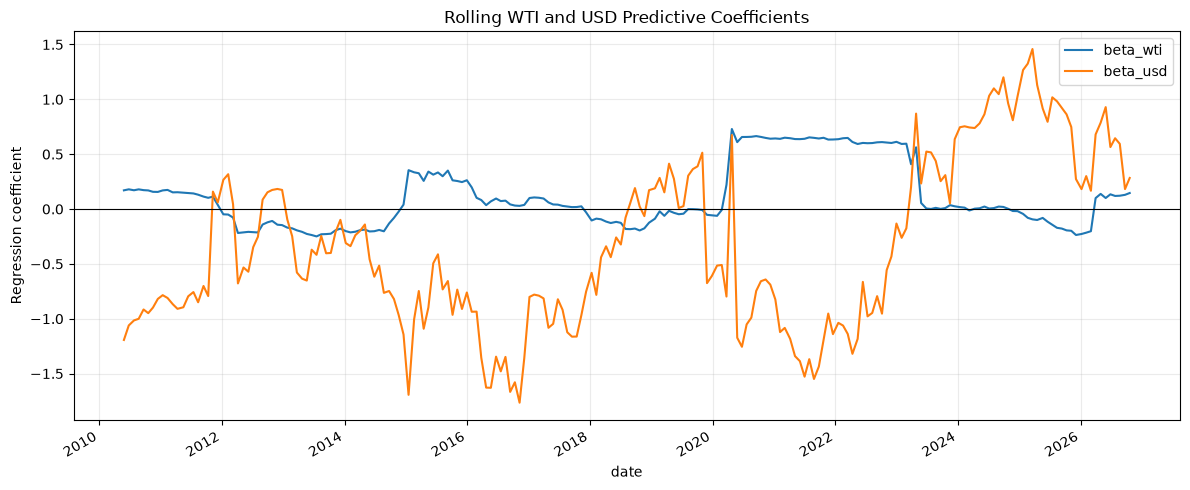

In [34]:

from sklearn.linear_model import LinearRegression

H = 15
lookback = 750

X = pd.DataFrame(index=df_var.index)
X["wti_5d"] = df_var["wti"].rolling(5).sum()
X["usd_5d"] = df_var["usd"].rolling(5).sum()

log_price = np.log(df_var["brent_spot"])
y = log_price.shift(-H) - log_price

coefficient_rows = []

for origin_idx in range(lookback + H, len(df_var), 20):

    train_end = origin_idx - H
    train_start = train_end - lookback + 1

    X_train = X.iloc[train_start:train_end + 1]
    y_train = y.iloc[train_start:train_end + 1]

    valid = X_train.notna().all(axis=1) & y_train.notna()

    model = LinearRegression()
    model.fit(X_train.loc[valid], y_train.loc[valid])

    coefficient_rows.append({
        "date": df_var.index[origin_idx],
        "beta_wti": model.coef_[0],
        "beta_usd": model.coef_[1],
        "intercept": model.intercept_
    })

coef_df = pd.DataFrame(coefficient_rows).set_index("date")

display(coef_df.tail())

coef_df[["beta_wti", "beta_usd"]].plot(
    figsize=(12, 5),
    title="Rolling WTI and USD Predictive Coefficients"
)

plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Regression coefficient")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [35]:

from statsmodels.stats.diagnostic import acorr_ljungbox

errors = (
    direct_wti_usd_val["actual"].to_numpy()
    - direct_wti_usd_val["forecast"].to_numpy()
)

lb_results = acorr_ljungbox(
    errors,
    lags=[5, 10, 15, 20],
    return_df=True
)

display(lb_results)


,lb_stat,lb_pvalue
5,1254.959335,3.654634e-269
10,1486.532858,0.000000e+00
15,1534.170458,0.000000e+00
20,1641.828671,0.000000e+00


In [36]:

import numpy as np
import pandas as pd
from scipy.stats import norm

def dm_test(rw, challenger, horizon=15, loss="absolute"):
    """
    DM-style equal predictive accuracy test.

    Positive DM statistic means challenger has
    lower average loss than random walk.

    HAC variance uses Bartlett weights
    and horizon - 1 lags.
    """

    keys = ["origin_date", "target_date"]

    a = rw[keys + ["actual", "forecast"]].merge(
        challenger[keys + ["actual", "forecast"]],
        on=keys,
        suffixes=("_rw", "_model"),
        validate="one_to_one"
    ).sort_values(keys).reset_index(drop=True)

    if len(a) != len(rw) or len(a) != len(challenger):
        raise ValueError("Forecast dates do not fully align")

    if not np.allclose(a["actual_rw"], a["actual_model"]):
        raise ValueError("Actual prices do not match")

    e_rw = a["actual_rw"].to_numpy() - a["forecast_rw"].to_numpy()
    e_model = a["actual_model"].to_numpy() - a["forecast_model"].to_numpy()

    if loss == "absolute":
        d = np.abs(e_rw) - np.abs(e_model)
    elif loss == "squared":
        d = e_rw**2 - e_model**2
    else:
        raise ValueError("loss must be absolute or squared")

    n = len(d)
    lag = min(horizon - 1, n - 1)

    centered = d - d.mean()

    # HAC long-run variance with Bartlett weights
    long_run_var = np.dot(centered, centered) / n

    for k in range(1, lag + 1):
        gamma_k = np.dot(
            centered[k:], centered[:-k]
        ) / n

        weight = 1 - k / (lag + 1)

        long_run_var += 2 * weight * gamma_k

    if long_run_var <= 0:
        raise ValueError("Non-positive HAC variance")

    dm_stat = d.mean() / np.sqrt(long_run_var / n)
    p_value = 2 * norm.sf(abs(dm_stat))

    return {
        "N": n,
        "Mean loss advantage": d.mean(),
        "DM statistic": dm_stat,
        "p-value": p_value
    }

print("DM test function ready!")


DM test function ready!


In [37]:

# H15 validation DM tests

dm_validation = pd.DataFrame({
    "Direct WTI + USD": dm_test(
        rw_val, direct_wti_usd_val, horizon=15
    ),
    "ARIMA(4,1,1)": dm_test(
        rw_val, arima15_val, horizon=15
    ),
    "XGBoost S1": dm_test(
        rw_val, val_models["XGBoost S1"], horizon=15
    )
}).T

display(dm_validation.round(5))


,N,Mean loss advantage,DM statistic,p-value
Direct WTI + USD,492.0,0.11072,1.59073,0.11167
"ARIMA(4,1,1)",492.0,0.00892,0.91405,0.36069
XGBoost S1,492.0,-0.00255,-0.19235,0.84747


In [38]:

# H15 test-period DM comparisons

dm_test_results = pd.DataFrame({
    "Direct WTI + USD": dm_test(
        rw_test, direct_wti_usd_test, horizon=15
    ),
    "ARIMA(4,1,1)": dm_test(
        rw_test, arima15_test, horizon=15
    ),
    "Historical Mean": dm_test(
        rw_test,
        test_models["Historical Mean"],
        horizon=15
    )
}).T

display(dm_test_results.round(5))


,N,Mean loss advantage,DM statistic,p-value
Direct WTI + USD,174.0,-0.54072,-2.83578,0.00457
"ARIMA(4,1,1)",174.0,-0.04426,-2.00431,0.04504
Historical Mean,174.0,0.03194,0.45473,0.64930


## 10. Economic benchmark: always long

Check whether historical-mean strategy results add value beyond maintaining a long exposure over the same schedules.

In [39]:

# Always-long benchmark using the same holding periods

always_long_results = rw_test.copy()

always_long_results["forecast"] = (
    always_long_results["origin_price"] * 1.01
)

benchmark_rows = []

for offset in range(H):
    metrics = economic_backtest(
        always_long_results,
        horizon=H,
        offset=offset
    )

    benchmark_rows.append({
        "offset": offset,
        **metrics
    })

always_long_summary = pd.DataFrame(benchmark_rows)

display(
    always_long_summary[
        ["offset", "trades", "total_return", "sharpe", "max_drawdown"]
    ].round(4)
)

print(
    "Mean always-long Sharpe:",
    round(always_long_summary["sharpe"].mean(), 4)
)


,offset,trades,total_return,sharpe,max_drawdown
0,0,12,0.9290,1.5765,-0.3929
1,1,12,0.8421,1.4929,-0.4244
2,2,12,0.8485,1.4680,-0.4349
3,3,12,0.9213,1.5578,-0.4107
4,4,12,0.9074,1.4731,-0.4574
5,5,12,0.7802,1.2257,-0.5042
6,6,12,0.8327,1.3528,-0.4468
7,7,12,0.6847,1.2280,-0.4401
8,8,12,0.6814,1.1486,-0.3972
9,9,11,0.8270,1.4211,-0.3795


Mean always-long Sharpe: 1.4516


## 11. Pre-validation time-series diagnostics

ACF/PACF and ADF are calculated using data before January 2024. ADF rejection of a unit root in log prices is not proof of a stable economic equilibrium.

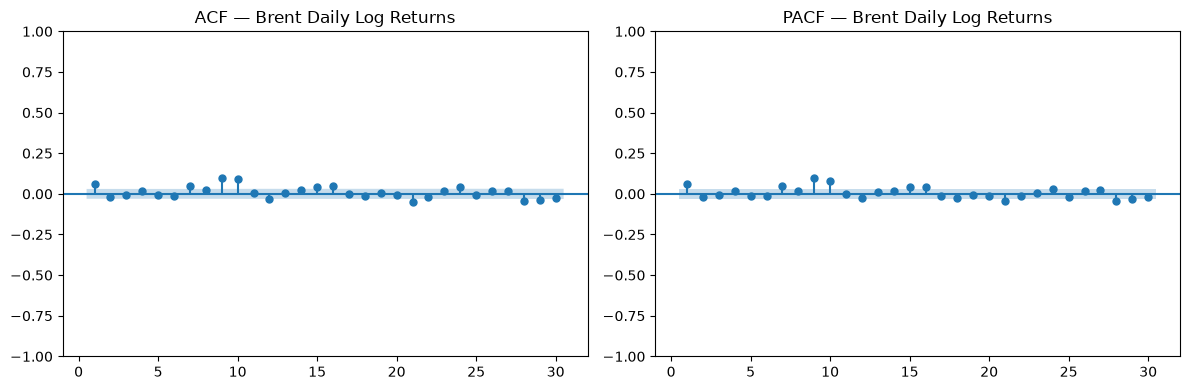

In [40]:

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from pathlib import Path

returns = df_var.loc[
    df_var.index < "2024-01-01",
    "log_return"
].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(
    returns,
    lags=30,
    ax=axes[0],
    zero=False
)

plot_pacf(
    returns,
    lags=30,
    ax=axes[1],
    zero=False,
    method="ywm"
)

axes[0].set_title("ACF — Brent Daily Log Returns")
axes[1].set_title("PACF — Brent Daily Log Returns")

plt.tight_layout()

output_dir = Path("../results")
output_dir.mkdir(exist_ok=True)

plt.savefig(
    output_dir / "h15_acf_pacf.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [41]:

from statsmodels.tsa.stattools import adfuller
import numpy as np
import pandas as pd

train_data = df_var.loc[df_var.index < "2024-01-01"]

log_prices = np.log(
    train_data["brent_spot"]
).dropna()

returns = train_data["log_return"].dropna()

def run_adf(series, name):
    result = adfuller(
        series,
        autolag="AIC"
    )

    return {
        "Series": name,
        "ADF Statistic": result[0],
        "p-value": result[1],
        "Lags Used": result[2],
        "Observations": result[3],
        "Stationary at 5%": result[1] < 0.05
    }

adf_results = pd.DataFrame([
    run_adf(log_prices, "Brent log prices"),
    run_adf(returns, "Brent log returns")
])

display(adf_results)


/var/folders/zc/msw43vhx5n90s_3fp97cqxdw0000gn/T/ipykernel_9272/2369334279.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
/var/folders/zc/msw43vhx5n90s_3fp97cqxdw0000gn/T/ipykernel_9272/2369334279.py:14: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(


,Series,ADF Statistic,p-value,Lags Used,Observations,Stationary at 5%
0,Brent log prices,-3.038747,3.143100e-02,25,4171,True
1,Brent log returns,-11.652367,2.022943e-21,28,4168,True


Pre-validation ADF tests reject the unit-root null for both Brent log prices (p = 0.0314) and log returns (p < 0.001), although the evidence for log prices is comparatively weaker. ACF/PACF plots show generally modest return autocorrelations with some isolated spikes. Ljung–Box tests reject no autocorrelation in overlapping 15-day forecast errors, while DM-style comparisons find no statistically significant validation improvement over random walk.

## 12. Consolidated results

The following cell collects the existing forecasts into one comparison table and exports it. **Lower errors are better.** Model selection must use validation rather than the already-examined test period.

In [42]:
# Final consolidated comparison; uses previously computed forecasts
final_validation = {**val_models, "ARIMA(4,1,1)": arima15_val,
                    "Direct WTI + USD": direct_wti_usd_val}
final_test = {**test_models, "ARIMA(4,1,1)": arima15_test,
              "Direct WTI + USD": direct_wti_usd_test}

rows = []
for name in final_validation:
    val = accuracy_metrics(final_validation[name])
    test = accuracy_metrics(final_test[name])
    rows.append({"Model": name, "Validation MAE": val["MAE"],
                 "Validation RMSE": val["RMSE"], "Validation MAPE (%)": val["MAPE"],
                 "Test MAE": test["MAE"], "Test RMSE": test["RMSE"],
                 "Test MAPE (%)": test["MAPE"]})
final_summary = pd.DataFrame(rows).sort_values("Validation MAPE (%)")
display(final_summary.round(4))
final_summary.to_csv(output_dir / "h15_all_model_metrics.csv", index=False)
print("Saved consolidated H15 metrics.")


,Model,Validation MAE,Validation RMSE,Validation MAPE (%),Test MAE,Test RMSE,Test MAPE (%)
6,Direct WTI + USD,3.3696,4.4448,4.4809,14.2725,18.0783,14.6441
5,"ARIMA(4,1,1)",3.4714,4.4955,4.6225,13.7760,17.4861,14.1515
4,XGBoost S1,3.4828,4.5172,4.6334,14.1493,17.6383,14.6343
0,Random Walk,3.4803,4.5052,4.6356,13.7318,17.4411,14.0968
3,VAR S1 p=3,3.4939,4.5235,4.6570,13.7861,17.4470,14.1662
1,Historical Mean,3.5129,4.5446,4.6847,13.6998,17.4213,14.0788
2,AR(1),3.5222,4.5542,4.6984,13.7114,17.4140,14.0850


Saved consolidated H15 metrics.


## Additional economic comparison — group-standard staggered backtest (H15)

This section uses a self-contained copy of the group’s `compare_models_staggered` methodology, matching the economic-return convention used by the H30/H60 notebooks. Every forecast origin opens a position, and the portfolio holds up to 15 staggered signals. The reported Sharpe is annualized from daily net portfolio returns.

This is **additional** to the earlier non-overlapping/offset robustness analysis, not a replacement. The group function charges 0.01% per unit change in net exposure; the earlier offset backtest uses a different cost assumption. Results should not be interpreted as executable futures trading P&L. The random-walk no-change strategy is flat, so its Sharpe is undefined.


In [43]:
import numpy as np
import pandas as pd

# Self-contained copy of the group's staggered convention.
# This avoids depending on an older local src.metrics module.
def economic_value_staggered_local(results, horizon, transaction_cost=0.0001):
    px = pd.concat([
        results.set_index("origin_date")["origin_price"],
        results.set_index("target_date")["actual"]
    ])
    px = px[~px.index.duplicated()].sort_index()
    ret = px.pct_change()
    sig = np.sign(results["forecast"] - results["origin_price"])
    sig.index = results["origin_date"]
    sig = sig.reindex(px.index)
    exposure = sig.shift(1).rolling(horizon).mean()
    turnover = exposure.diff().abs()
    net = exposure * ret - transaction_cost * turnover
    full = sig.notna().to_numpy() & exposure.notna().to_numpy()
    net = net[full].iloc[1:]
    exposure = exposure[full].iloc[1:]
    turnover = turnover[full].iloc[1:]
    ann_ret = net.mean() * 252
    ann_vol = net.std() * np.sqrt(252)
    equity = (1 + net).cumprod()
    return {
        "annualized_return": ann_ret,
        "annualized_vol": ann_vol,
        "sharpe_ratio": ann_ret / ann_vol if ann_vol > 0 else np.nan,
        "max_drawdown": (equity / equity.cummax() - 1).min(),
        "avg_gross_exposure": exposure.abs().mean(),
        "pct_time_net_long": (exposure > 0).mean(),
        "annual_turnover": turnover.mean() * 252,
        "n_days": len(net),
    }

def compare_models_staggered_local(results_dict, horizon):
    return pd.DataFrame({
        name: economic_value_staggered_local(frame, horizon)
        for name, frame in results_dict.items()
    }).T


# Same test forecasts already computed above; no model refitting.
staggered_models = {
    **test_models,
    "ARIMA(4,1,1)": arima15_test,
    "Direct WTI + USD": direct_wti_usd_test,
}

# Confirm matching dates and prices across models.
reference = staggered_models["Random Walk"].reset_index(drop=True)
for name, frame in staggered_models.items():
    candidate = frame.reset_index(drop=True)
    assert len(candidate) == len(reference), name
    assert candidate["origin_date"].equals(reference["origin_date"]), name
    assert candidate["target_date"].equals(reference["target_date"]), name
    assert np.allclose(candidate["actual"], reference["actual"]), name

# Benchmark for market exposure: always long.
always_long_staggered = reference.copy()
always_long_staggered["forecast"] = always_long_staggered["origin_price"] * 1.01
staggered_models["Always Long"] = always_long_staggered

staggered_summary = compare_models_staggered_local(
    staggered_models,
    horizon=15
)
display(staggered_summary[[
    "annualized_return", "annualized_vol", "sharpe_ratio",
    "max_drawdown", "annual_turnover", "avg_gross_exposure", "n_days"
]].round(4))

# The group implementation assumes a consecutive trading-day path.
# Confirm the reconstructed path matches the cleaned dataset.
px = pd.concat([
    reference.set_index("origin_date")["origin_price"],
    reference.set_index("target_date")["actual"]
])
px = px[~px.index.duplicated()].sort_index()
expected = df_var["brent_spot"].reindex(px.index)
assert np.allclose(px.to_numpy(), expected.to_numpy(), equal_nan=False)
print("Staggered portfolio path aligned with cleaned Brent data.")


,annualized_return,annualized_vol,sharpe_ratio,max_drawdown,annual_turnover,avg_gross_exposure,n_days
Random Walk,0.0000,0.0000,NaN,0.0000,0.0000,0.0000,158.0
Historical Mean,1.0074,0.7076,1.4237,-0.5042,0.0000,1.0000,158.0
AR(1),0.7989,0.5602,1.4262,-0.3879,8.5063,0.7359,158.0
VAR S1 p=3,-0.0165,0.2725,-0.0605,-0.2884,16.5873,0.3823,158.0
XGBoost S1,-1.0263,0.5662,-1.8126,-0.6230,8.7190,0.8312,158.0
"ARIMA(4,1,1)",-0.2996,0.1902,-1.5755,-0.2420,14.6734,0.2481,158.0
Direct WTI + USD,-1.0397,0.3921,-2.6517,-0.5476,15.0987,0.4616,158.0
Always Long,1.0074,0.7076,1.4237,-0.5042,0.0000,1.0000,158.0


Staggered portfolio path aligned with cleaned Brent data.


## 14. Final interpretation and limitations

**Forecast accuracy.** The direct WTI + USD regression achieved the lowest exploratory validation MAPE (4.4809%, versus 4.6356% for random walk), but deteriorated in the 2026 test (14.6441%, versus 14.0968% for random walk). ARIMA(4,1,1) improved validation marginally (4.6225%) but not testing (14.1515%). Historical mean had the lowest observed test MAPE (14.0788%), a retrospective ranking rather than an ex-ante model-selection result. Approximate HAC DM-style tests found no significant validation improvement for the examined challengers.

**Economic validity.** Under the group's *daily staggered* strategy (158 daily portfolio-return observations), AR(1) had Sharpe 1.4262, virtually identical to always-long (1.4237); historical mean matched always-long exactly (1.4237). VAR, XGBoost, ARIMA and direct WTI + USD had negative staggered Sharpe ratios. Thus no robust incremental trading value beyond simple market exposure was established. The separate *non-overlapping* analysis is retained as an entry-date sensitivity check: ARIMA's offset-0 Sharpe of 4.51 was not representative of its alternative offsets (mean -0.26). These Sharpe ratios use different portfolio constructions and cost assumptions and should not be compared directly.

**Robustness and limitations.** Test-period daily return volatility was approximately 2.39 times validation volatility. Rolling WTI/USD coefficients varied over time, but this is not proof of a structural break. Overlapping H15 forecast targets, repeated model exploration and reuse of the 2026 test sample limit statistical inference. The staggered simulation uses spot-price returns as a proxy, daily netted exposure, 0.01% cost per unit of *net exposure change*, and omits futures rolls, financing and execution frictions. Its reported annualized return is an arithmetic mean-based approximation, not a compounded annual investment return. Ljung-Box results on overlapping forecast errors are not a conventional one-step residual diagnostic. The exploratory misaligned ARIMAX experiment is not evidence against properly specified ARIMAX.

**Conclusion.** Validation improvements did not translate into robust test-period or economic gains. Random walk and always-long remain essential statistical and economic benchmarks.
